# Economics Visualisation Lab — Matplotlib and Seaborn
Dataset: built-in Longley macroeconomic dataset from statsmodels.
It contains annual US data from 1947–1962 (16 observations). It is useful for
learning chart construction and interpretation, but too small/historical for
current economic conclusions. See statsmodels documentation:
https://www.statsmodels.org/stable/datasets/generated/longley.html


## Learning outcomes

By completing this notebook, you will be able to:

- Distinguish a Matplotlib **Figure** from an **Axes** object.
- Create line charts, bar charts, scatter plots and histograms.
- Use Seaborn for histograms, KDE, boxplots, regression plots and correlation heatmaps.
- Format and save figures in PNG, PDF and SVG formats.
- Choose charts to match research questions and identify misleading scales.



## 1. IMPORT LIBRARIES AND SETUP


In [8]:
from pathlib import Path #imports a helper for handling folder and file paths. It helps Python create paths that work across operating systems.
import pandas as pd #managing tabular data
import matplotlib.pyplot as plt #plotting commands
import seaborn as sns #library for statistical charts
import statsmodels.api as sm #for accessing built-in Longley dataset
from matplotlib.ticker import FuncFormatter, MultipleLocator #imports tools for changing axis labels and tick spacing

In [9]:
OUT = Path("economics_visualisation_outputs") #names the output folder
OUT.mkdir(exist_ok=True) #creates it and does not complain if the folder exists

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.dpi": 110,       # display resolution
    "savefig.dpi": 300,      # print/report resolution
    "font.family": "DejaVu Sans",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

print("Setup complete. Figures will be saved to:", OUT.resolve())

Setup complete. Figures will be saved to: C:\Users\SRMAP\economics_visualisation_outputs


In [10]:
plt.savefig("my_chart.png") #only for saving a figure without specifying the path

<Figure size 880x550 with 0 Axes>

## 2. LOAD SAMPLE DATA FROM A PYTHON LIBRARY


In [11]:
# Longley is bundled with statsmodels: no separate CSV download is needed.
dataset = sm.datasets.longley.load_pandas() #asks Statsmodels for its built-in Longley dataset in a Pandas-friendly format and stores the returned object under the name dataset
df = dataset.data.copy() #creates a seprate copy of data after extracting the actual table under the Df(dataframe)

In [12]:
df

,TOTEMP,GNPDEFL,GNP,UNEMP,ARMED,POP,YEAR
0,60323.0,83.0,234289.0,2356.0,1590.0,107608.0,1947.0
1,61122.0,88.5,259426.0,2325.0,1456.0,108632.0,1948.0
2,60171.0,88.2,258054.0,3682.0,1616.0,109773.0,1949.0
3,61187.0,89.5,284599.0,3351.0,1650.0,110929.0,1950.0
4,63221.0,96.2,328975.0,2099.0,3099.0,112075.0,1951.0
5,63639.0,98.1,346999.0,1932.0,3594.0,113270.0,1952.0
6,64989.0,99.0,365385.0,1870.0,3547.0,115094.0,1953.0
7,63761.0,100.0,363112.0,3578.0,3350.0,116219.0,1954.0
8,66019.0,101.2,397469.0,2904.0,3048.0,117388.0,1955.0
9,67857.0,104.6,419180.0,2822.0,2857.0,118734.0,1956.0


In [30]:
# Rename columns to readable lowercase names for convenient use.
df = df.rename(columns={
    "TOTEMP": "employment",
    "GNPDEFL": "gnp_deflator",
    "GNP": "gnp",
    "UNEMP": "unemployed",
    "ARMED": "armed_forces",
    "POP": "population",
    "YEAR": "year"
})
df["year"] = df["year"].astype(int) #converts the year to an integer rather than a decimal number.

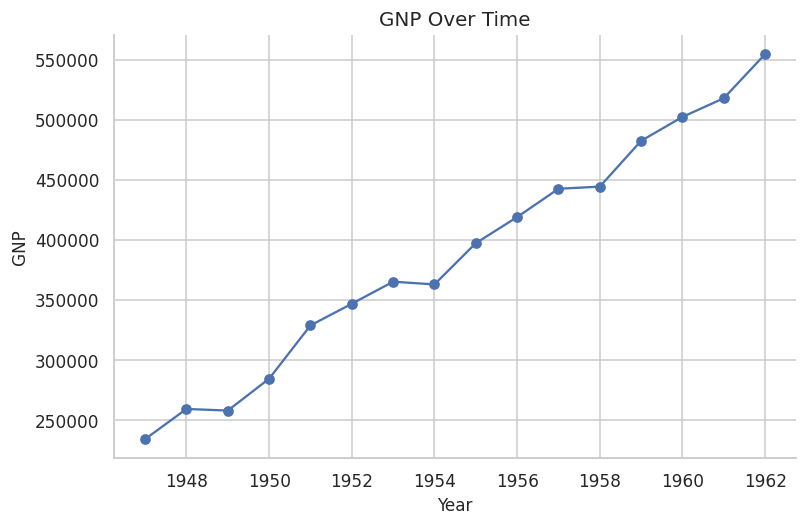

In [31]:
plt.plot(df["year"], df["gnp"], marker="o")
plt.title("GNP Over Time")
plt.xlabel("Year")
plt.ylabel("GNP")
plt.show()

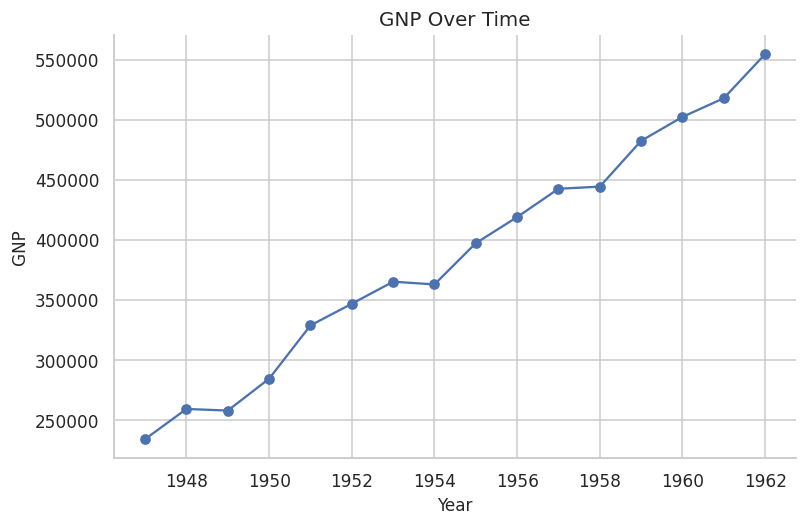

In [15]:
plt.plot(df["year"], df["gnp"], marker="o")
plt.title("GNP Over Time")
plt.xlabel("Year")
plt.ylabel("GNP")

plt.savefig("GNP_figure.png", dpi=300, bbox_inches="tight") #saving a figure by default in the workign directory
plt.show()

In [13]:
import os
print(os.getcwd()) #knowing my working directory to see the figure location 

C:\Users\SRMAP


In [16]:
plt.savefig(  
    r"C:\Users\SRMAP\Documents\GNP_figure.png", #saving directly to a specific folder
    dpi=300,
    bbox_inches="tight"
)

<Figure size 880x550 with 0 Axes>

In [17]:
# Save the data as a CSV file for later file-reading practice.
df.to_csv(OUT / "longley_economic_data.csv", index=False) #saves the table as a CSV file, avoids adding an extra endex column

print("\nFirst five rows:\n", df.head())
print("\nRows and columns:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nSummary statistics:\n", df.describe().round(2))
print("\nMissing values:\n", df.isna().sum())


First five rows:
    employment  gnp_deflator       gnp  unemployed  armed_forces  population  \
0     60323.0          83.0  234289.0      2356.0        1590.0    107608.0   
1     61122.0          88.5  259426.0      2325.0        1456.0    108632.0   
2     60171.0          88.2  258054.0      3682.0        1616.0    109773.0   
3     61187.0          89.5  284599.0      3351.0        1650.0    110929.0   
4     63221.0          96.2  328975.0      2099.0        3099.0    112075.0   

   year  
0  1947  
1  1948  
2  1949  
3  1950  
4  1951  

Rows and columns: (16, 7)

Column names: ['employment', 'gnp_deflator', 'gnp', 'unemployed', 'armed_forces', 'population', 'year']

Data types:
 employment      float64
gnp_deflator    float64
gnp             float64
unemployed      float64
armed_forces    float64
population      float64
year              int64
dtype: object

Summary statistics:
        employment  gnp_deflator        gnp  unemployed  armed_forces  \
count       16.00       

In [ ]:
# Optional: read the saved CSV back into a DataFrame.
df_csv = pd.read_csv(OUT / "longley_economic_data.csv")
print("\nCSV read-back shape:", df_csv.shape)

## 3. MATPLOTLIB: FIGURE AND AXES


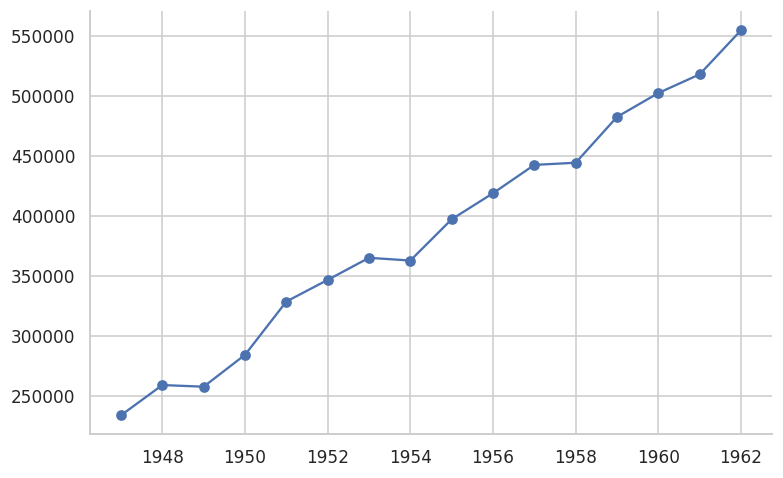

In [18]:
plt.plot(df["year"], df["gnp"], marker="o")
plt.show()

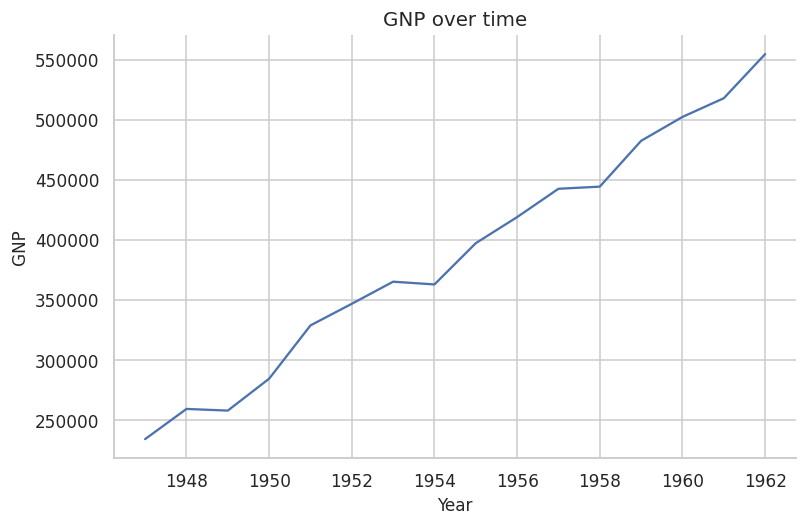

In [19]:
plt.plot(df["year"], df["gnp"])
plt.title("GNP over time")
plt.xlabel("Year")
plt.ylabel("GNP")
plt.show()

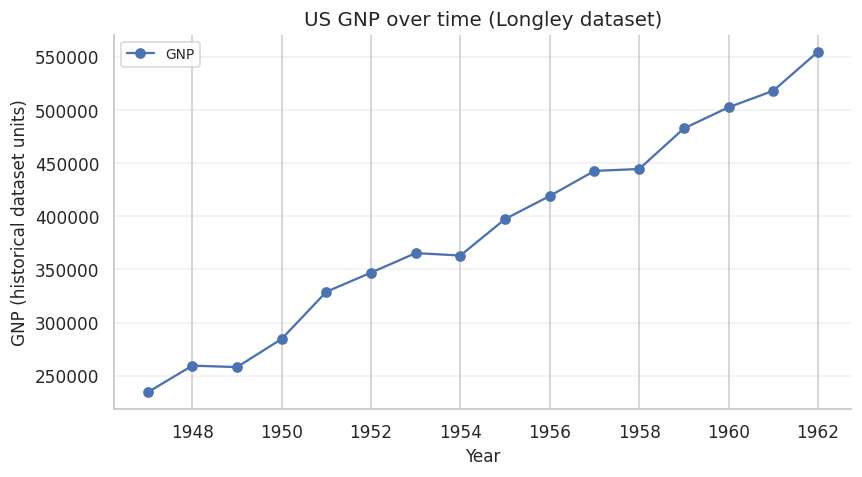

In [20]:
# Figure = complete canvas. Axes = plotting area inside the canvas.
fig, ax = plt.subplots(figsize=(8, 4.5)) #creates a figure(canvas) and an Axes (plotting area) and sets the figure size in inches
ax.plot(df["year"], df["gnp"], marker="o", label="GNP") #draws a line: year goes on the horizontal x-axis and GNP on the vertical y-axis.Marker places a circular mark at each observation
ax.set_title("US GNP over time (Longley dataset)")  #adds a title and axis labels
ax.set_xlabel("Year")
ax.set_ylabel("GNP (historical dataset units)")
ax.legend() #displays the label
ax.grid(axis="y", alpha=0.3) #adds faint horizontal gridlines; alpha controls transparency.
fig.tight_layout() # adjusts spacing to reduce overlaps.
fig.savefig(OUT / "01_figure_axes.png", dpi=300, bbox_inches="tight") #saves the figure in a high resolution setting; trims the excess whitespace
plt.show() #displays the chart
 

## 4. LINE CHART


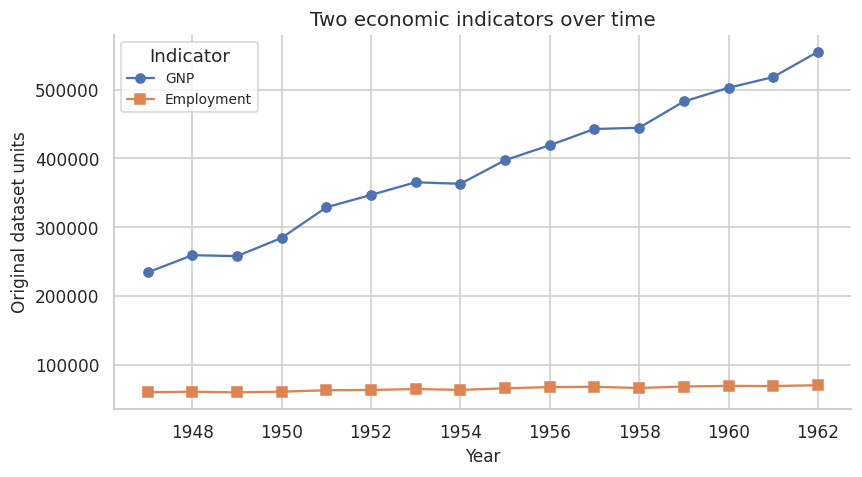

In [21]:
# Use for ordered values, especially trends over time.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df["year"], df["gnp"], marker="o", label="GNP")
ax.plot(df["year"], df["employment"], marker="s", label="Employment")
ax.set_title("Two economic indicators over time")
ax.set_xlabel("Year")
ax.set_ylabel("Original dataset units")
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.legend(title="Indicator")
fig.tight_layout()
fig.savefig(OUT / "02_line_chart.png", dpi=300, bbox_inches="tight")
plt.show()
# Caution: the series have different scales. Do not infer relative magnitude
# from their line heights; use separate panels or indexed values for comparison.


## 5. BAR CHART


In [22]:
plt.bar(categories, values) #replace categories and values as per your data
plt.show()

NameError: name 'categories' is not defined

In [23]:
df["GNP_r"] = pd.cut(
    df["gnp"],
    bins=[0, 300000, 400000, 600000],
    labels=["low", "Middle", "High"]
)


In [24]:
early = df.loc[df["year"].between(1947, 1950), "gnp"].mean()
middle = df.loc[df["year"].between(1951, 1955), "gnp"].mean()
late = df.loc[df["year"].between(1956, 1962), "gnp"].mean()

means = pd.Series({
    "1947–1950": early,
    "1951–1955": middle,
    "1956–1962": late
}) #other way to recode/categorise the variables

In [25]:
df

,employment,gnp_deflator,gnp,unemployed,armed_forces,population,year,GNP_r
0,60323.0,83.0,234289.0,2356.0,1590.0,107608.0,1947,low
1,61122.0,88.5,259426.0,2325.0,1456.0,108632.0,1948,low
2,60171.0,88.2,258054.0,3682.0,1616.0,109773.0,1949,low
3,61187.0,89.5,284599.0,3351.0,1650.0,110929.0,1950,low
4,63221.0,96.2,328975.0,2099.0,3099.0,112075.0,1951,Middle
5,63639.0,98.1,346999.0,1932.0,3594.0,113270.0,1952,Middle
6,64989.0,99.0,365385.0,1870.0,3547.0,115094.0,1953,Middle
7,63761.0,100.0,363112.0,3578.0,3350.0,116219.0,1954,Middle
8,66019.0,101.2,397469.0,2904.0,3048.0,117388.0,1955,Middle
9,67857.0,104.6,419180.0,2822.0,2857.0,118734.0,1956,High


In [ ]:
df

In [ ]:
plt.bar(df["year"], ["GNP_r"])
plt.show()

In [31]:
# Bars compare categories or defined groups.
df["period"] = pd.cut( #divides a numerical variable (year) into named intervals.
    df["year"],
    bins=[1946, 1950, 1955, 1962], #interval boundaries
    labels=["1947–1950", "1951–1955", "1956–1962"], #assigning names to the intervals
    include_lowest=True   #includes the lowest boundary
)
period_mean = df.groupby("period", observed=False)["gnp"].mean()   #calculates average GNP within each period.

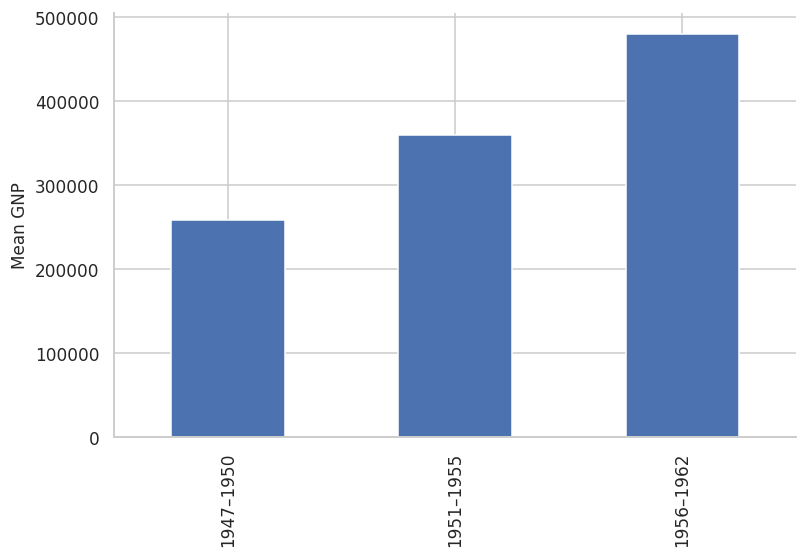

In [35]:
means.plot(kind="bar")
plt.ylabel("Mean GNP")
plt.show()

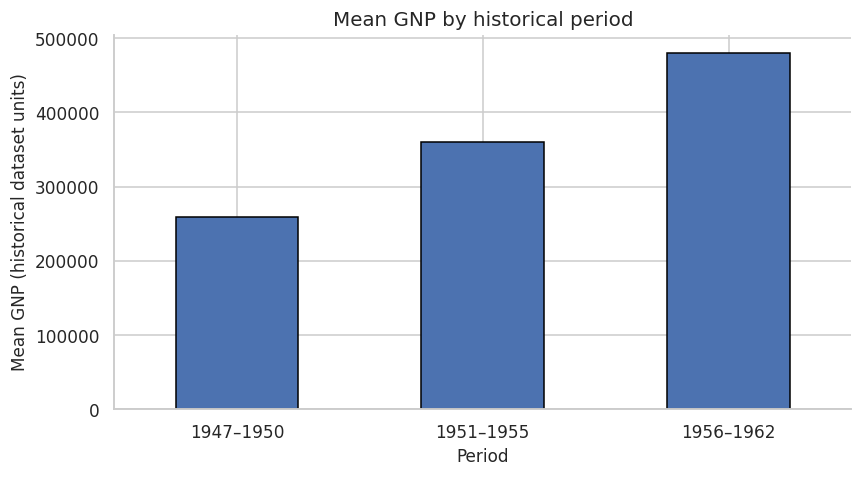

In [32]:
fig, ax = plt.subplots(figsize=(8, 4.5))
period_mean.plot(kind="bar", ax=ax, edgecolor="black") #creates a bar chart on the supplied Axes.
ax.set_title("Mean GNP by historical period")
ax.set_xlabel("Period")
ax.set_ylabel("Mean GNP (historical dataset units)")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(OUT / "03_bar_chart.png", dpi=300, bbox_inches="tight")
plt.show()

## 6. SCATTER PLOT-For examining relationships


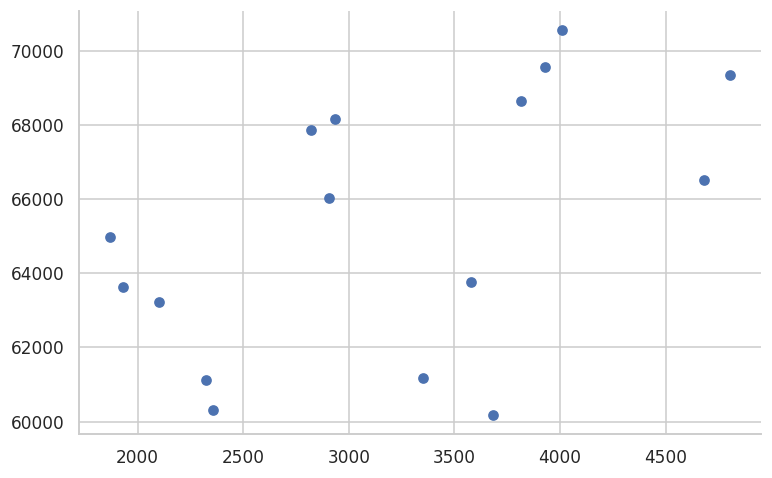

In [23]:
plt.scatter(df["unemployed"], df["employment"])
plt.show()

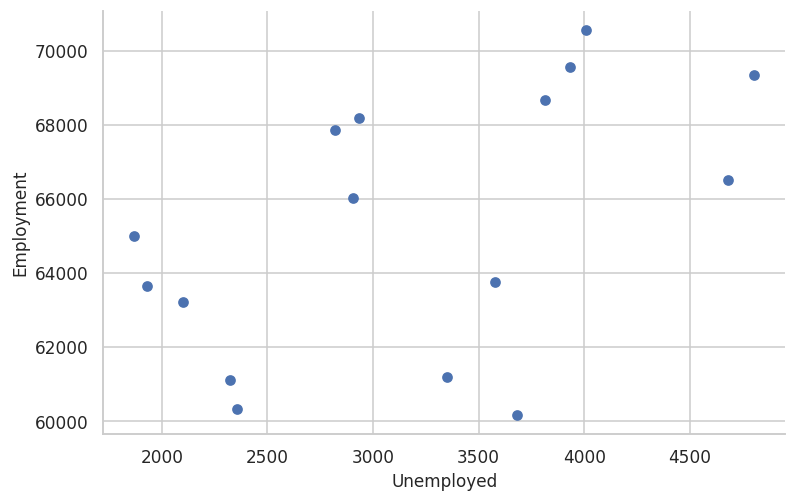

In [36]:
plt.scatter(df["unemployed"], df["employment"])
plt.xlabel("Unemployed")
plt.ylabel("Employment")
plt.show()

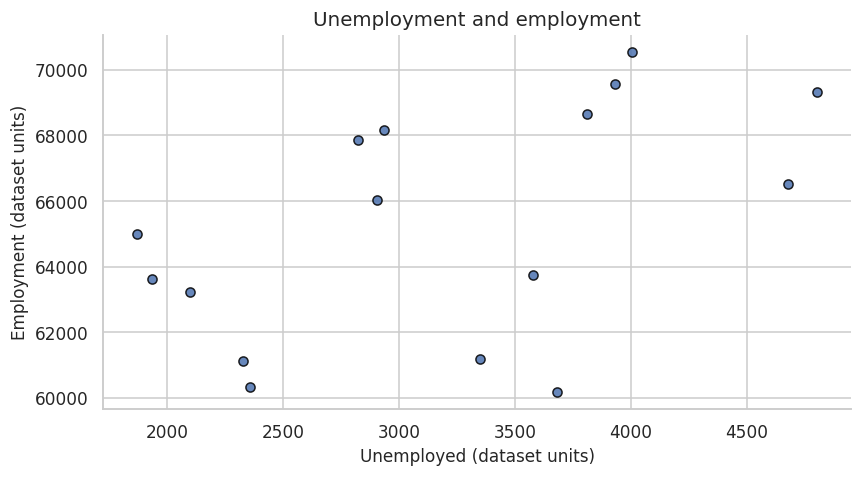

In [24]:
# Use to explore the relationship between two numeric variables.
fig, ax = plt.subplots(figsize=(8, 4.5)) #places one dot for each observation; it does not connect the dots.
ax.scatter(df["unemployed"], df["employment"], alpha=0.85, edgecolor="black") #alpha makes points slightly transparent and edgecolor draws a border around each point.
ax.set_title("Unemployment and employment")
ax.set_xlabel("Unemployed (dataset units)")
ax.set_ylabel("Employment (dataset units)")
fig.tight_layout()
fig.savefig(OUT / "04_scatter_plot.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. HISTOGRAM - to examine distributions


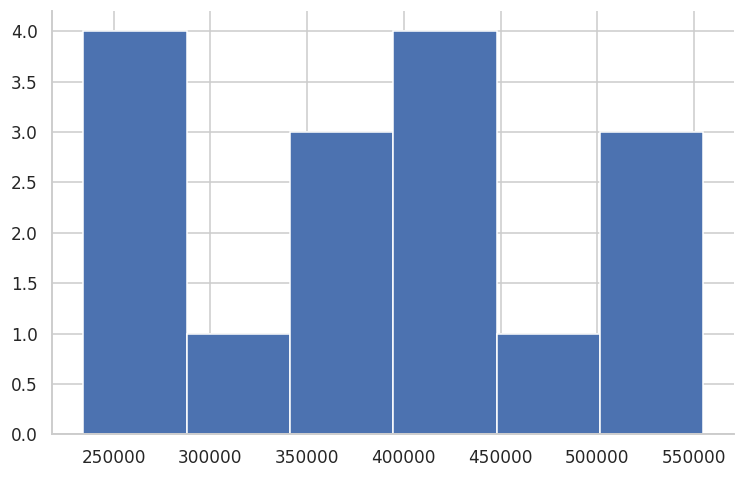

In [22]:
plt.hist(df["gnp"], bins=6)
plt.show()

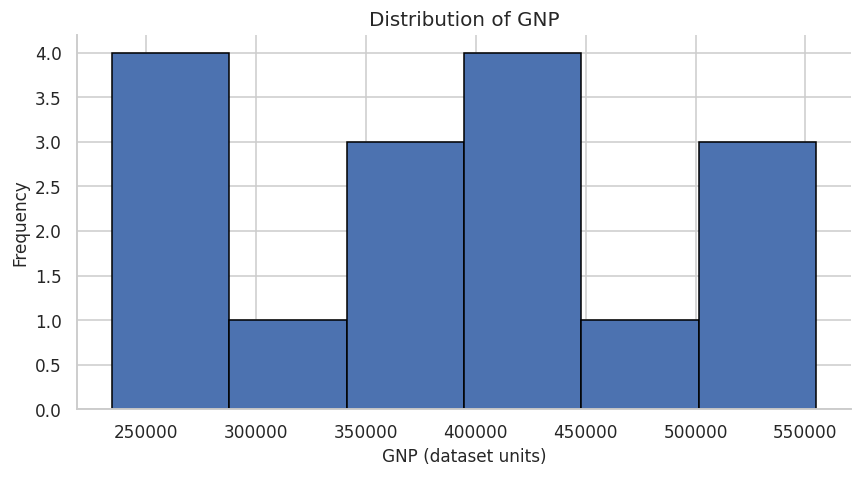

In [10]:
# A histogram shows the distribution of one numeric variable.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["gnp"], bins=6, edgecolor="black")
ax.set_title("Distribution of GNP")
ax.set_xlabel("GNP (dataset units)")
ax.set_ylabel("Frequency")
fig.tight_layout()
fig.savefig(OUT / "05_histogram.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. TITLES, LABELS, LEGENDS AND AXIS FORMATTING


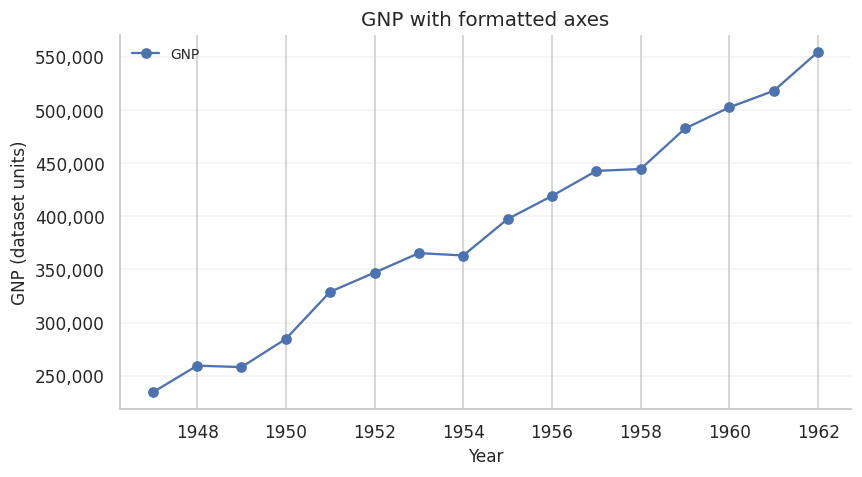

In [11]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df["year"], df["gnp"], marker="o", label="GNP")
ax.set_title("GNP with formatted axes")
ax.set_xlabel("Year")
ax.set_ylabel("GNP (dataset units)")
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(OUT / "06_axis_formatting.png", dpi=300, bbox_inches="tight")
plt.show()


## 9. SEABORN: HISTOGRAM + KDE


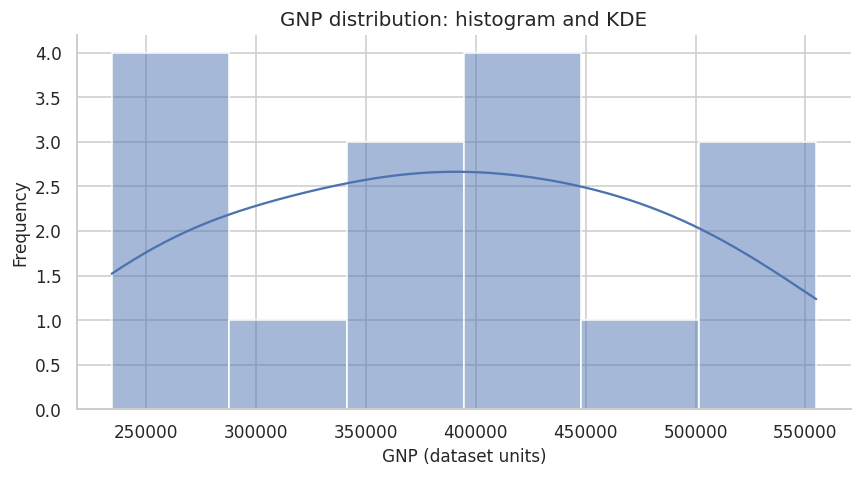

In [12]:
# KDE is a smoothed distribution estimate. With only 16 observations, treat
# its shape cautiously; it is demonstrated here for learning the command.
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(data=df, x="gnp", bins=6, kde=True, ax=ax)
ax.set_title("GNP distribution: histogram and KDE")
ax.set_xlabel("GNP (dataset units)")
ax.set_ylabel("Frequency")
fig.tight_layout()
fig.savefig(OUT / "07_histogram_kde.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. SEABORN: BOXPLOT


In [ ]:
sns.boxplot(y=df["gnp"])
plt.show()

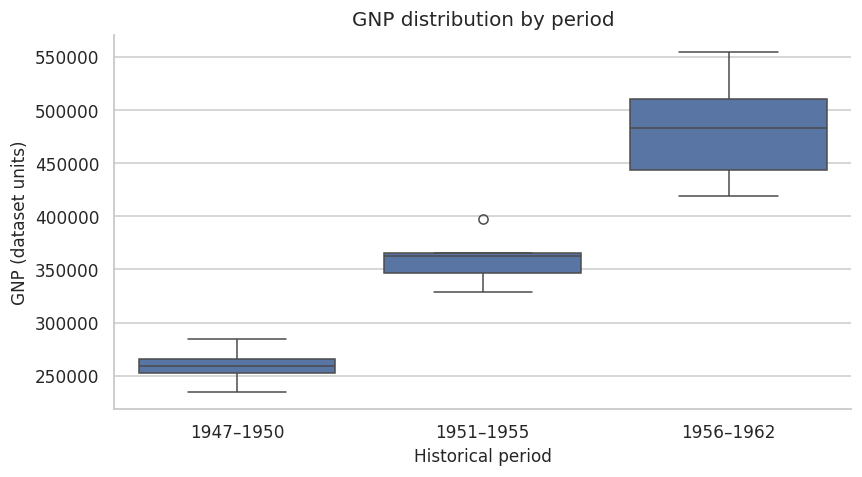

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=df, x="period", y="gnp", ax=ax)
ax.set_title("GNP distribution by period")
ax.set_xlabel("Historical period")
ax.set_ylabel("GNP (dataset units)")
fig.tight_layout()
fig.savefig(OUT / "08_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()


## 11. SEABORN: REGRESSION PLOT


In [ ]:
sns.regplot(x="unemployed", y="employment", data=df)
plt.show()

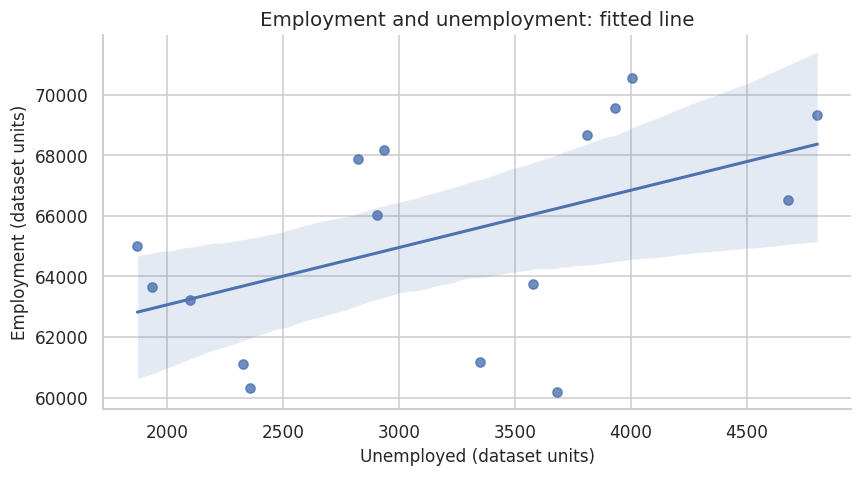


Correlation:
             unemployed  employment
unemployed       1.000       0.502
employment       0.502       1.000
Correlation is association, not proof of causality.


In [14]:
# regplot adds a fitted linear line. It does not prove causation.
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=df, x="unemployed", y="employment", ax=ax,
            scatter_kws={"alpha": 0.8}, line_kws={"linewidth": 2})
ax.set_title("Employment and unemployment: fitted line")
ax.set_xlabel("Unemployed (dataset units)")
ax.set_ylabel("Employment (dataset units)")
fig.tight_layout()
fig.savefig(OUT / "09_regplot.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nCorrelation:\n", df[["unemployed", "employment"]].corr().round(3))
print("Correlation is association, not proof of causality.")


## 12. SEABORN: CORRELATION HEATMAP


In [ ]:
corr = df[["gnp", "employment", "population"]].corr()
sns.heatmap(corr, annot=True)
plt.show()

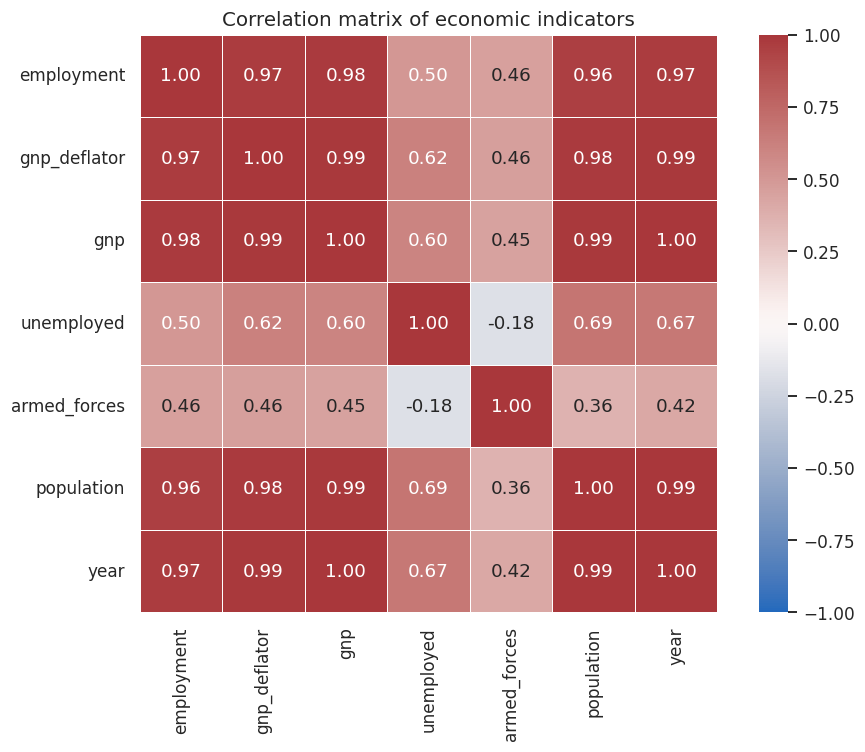

In [15]:
corr = df.select_dtypes(include="number").corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix of economic indicators")
fig.tight_layout()
fig.savefig(OUT / "10_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()


## 13. CONSISTENT STYLING AND COLOUR


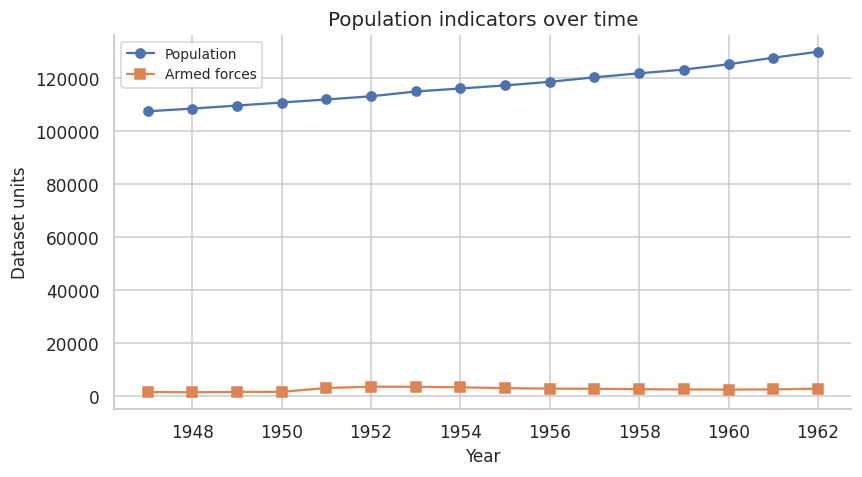

In [16]:
# Use a restrained, consistent style. Colour should help distinguish data,
# not decorate the figure.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(df["year"], df["population"], marker="o", label="Population")
ax.plot(df["year"], df["armed_forces"], marker="s", label="Armed forces")
ax.set_title("Population indicators over time")
ax.set_xlabel("Year")
ax.set_ylabel("Dataset units")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "11_consistent_style.png", dpi=300, bbox_inches="tight")
plt.show()


## 14. SAVE FOR REPORTS AND PAPERS


In [ ]:
plt.savefig("my_chart.png", dpi=300, bbox_inches="tight")

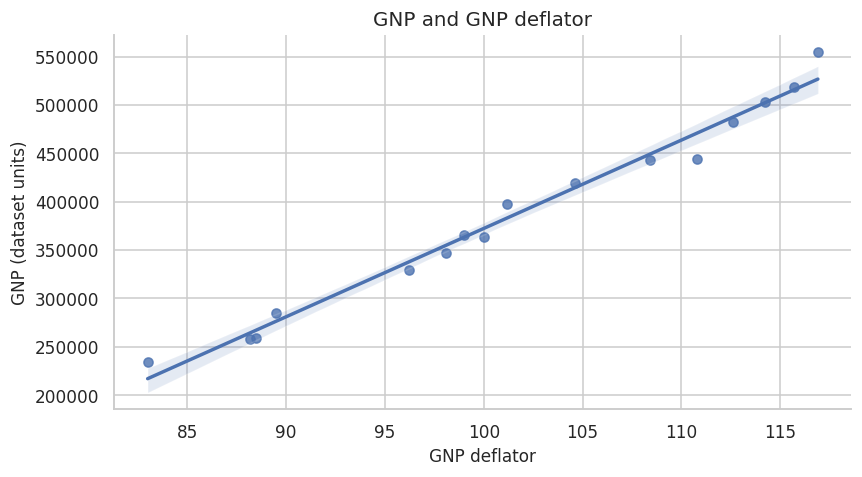

In [17]:
# PNG is convenient for documents/slides; PDF and SVG are vector formats.
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.regplot(data=df, x="gnp_deflator", y="gnp", ax=ax)
ax.set_title("GNP and GNP deflator")
ax.set_xlabel("GNP deflator")
ax.set_ylabel("GNP (dataset units)")
fig.tight_layout()
fig.savefig(OUT / "12_publication_figure.png", dpi=300, bbox_inches="tight")
fig.savefig(OUT / "12_publication_figure.pdf", bbox_inches="tight")
fig.savefig(OUT / "12_publication_figure.svg", bbox_inches="tight")
plt.show()


## 15. COMMON MISTAKE: TRUNCATED AXIS


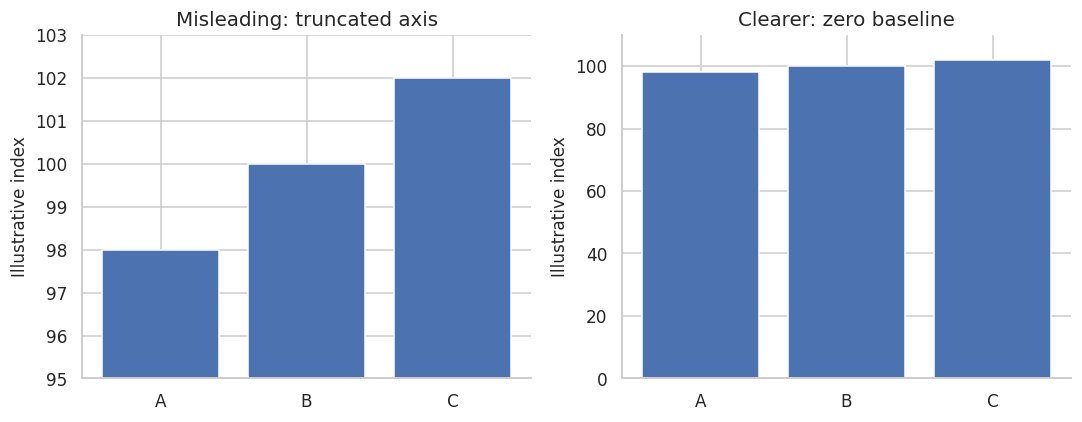

In [18]:
# Bar lengths encode magnitude, so a zero baseline is usually appropriate.
# Left panel is intentionally misleading; right panel is a clearer comparison.
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
values = [98, 100, 102]
axes[0].bar(["A", "B", "C"], values)
axes[0].set_ylim(95, 103)
axes[0].set_title("Misleading: truncated axis")
axes[0].set_ylabel("Illustrative index")
axes[1].bar(["A", "B", "C"], values)
axes[1].set_ylim(0, 110)
axes[1].set_title("Clearer: zero baseline")
axes[1].set_ylabel("Illustrative index")
fig.tight_layout()
fig.savefig(OUT / "13_truncated_axis_warning.png", dpi=300, bbox_inches="tight")
plt.show()


## 16. CHOOSING THE RIGHT CHART


In [ ]:
chart_guide = pd.DataFrame({
    "Research question": [
        "How does GDP change over time?",
        "How do categories compare?",
        "What is the distribution of income?",
        "Are education and wages associated?",
        "How does a distribution differ across groups?",
        "How are several numeric indicators correlated?"
    ],
    "Suggested chart": [
        "Line chart",
        "Bar chart",
        "Histogram / KDE",
        "Scatter plot / regplot",
        "Boxplot",
        "Correlation heatmap"
    ]
})
print("\nChart selection guide:\n", chart_guide.to_string(index=False))


## 17. PRACTICE TASKS


In [ ]:
# 1. Replace GNP with population in the line chart.
# 2. Change histogram bins from 6 to 4 and 10. What changes?
# 3. Add a legend to the scatter plot after creating a second series.
# 4. Save a figure as PNG and PDF.
# 5. Why are GNP and employment line heights not directly comparable in Section 4?
# 6. Explain the problem with the truncated axis in Section 15.
# 7. Choose a chart for inflation over time, GDP by country, income distribution,
#    and education versus wages.
# 8. Why does a regression line not prove a causal relationship?

print("\nLAB COMPLETE.")
print("Dataset CSV and figures are saved in:", OUT.resolve())
print("Review the output folder for PNG, PDF, SVG, and CSV files.")


In [ ]:
df

In [27]:
import statsmodels as sm
import statsmodels.formula.api as smf

In [39]:
model = smf.ols("gnp~population", data=df).fit()
#.fit() estimates the model

In [ ]:
print(model.summary())
# .summary() displays the results.

In [43]:
model.params       # Regression coefficients

Intercept    -1.275210e+06
population    1.416157e+01
dtype: float64

In [44]:
model.bse          # Standard errors

Intercept     59825.597946
population        0.508648
dtype: float64

In [45]:
model.pvalues      # P-values

Intercept     4.526839e-12
population    1.167567e-13
dtype: float64

In [ ]:
model.conf_int()   # Confidence intervals

In [73]:
model.rsquared     # R-squared

np.float64(0.9920345180557703)

In [ ]:
model.fittedvalues # Predicted values for the estimation sample

In [ ]:
model.resid        # Regression residuals

In [46]:
model = smf.ols("gnp~population + armed_forces", data=df).fit() #multiple regression

In [ ]:
print(model.summary())

In [ ]:
#regression with an interaction
model = smf.ols("employment~gnp*unemployed", data=df).fit()
print(model.summary())

In [ ]:
model = smf.ols("gnp~population + C(armed_forces)", data=df).fit() # C treats a variable as categorical in regression
print(model.summary())

In [ ]:
model = smf.ols("gnp~population + C(armed_forces)", data=df).fit(cov_type="HC3")
print(model.summary())
# HC3 adjusts the estimated standard errors for heteroskedasticity

In [ ]:
#interaction effect
model = smf.ols("gnp~population*armed_forces", data=df).fit(cov_type="HC3")
print(model.summary())

In [ ]:
#non-linear associations:quadratic models
quadratic = smf.ols(
    "gnp~population*armed_forces + I(gnp_deflator**2)",
    data=df
).fit(cov_type="HC3")
print(quadratic.summary())

## write formulas for log models
Level-level	y ~ x	Outcome units per one-unit rise in x
Log-level	np.log(y) ~ x	Approx. 100*β percent change in y; exact 100*(exp(β)-1)%
Level-log	y ~ np.log(x)	1% rise in x ≈ β/100 outcome units
Log-log	np.log(y) ~ np.log(x)	β is an elasticity

In [ ]:
log_level = smf.ols(
    "np.log(gnp) ~ population + armed_forces + gnp_deflator",
    data=df
).fit(cov_type="HC3")
print(log_level.summary())

In [ ]:
df

## 18. Economic unit conversion
Conversions depend on units. ₹1 crore = ₹10 million; ₹100 crore = ₹1 billion. If GDP is in ₹ crore and population is in millions, dividing the numerical values and multiplying by 10 gives rupees per person.

In [ ]:
df["TOTEMP_million"] = df["employment"] / 1000 #Convert values into thousands and millions

df[["employment", "TOTEMP_million"]].head()

In [102]:
df["GNP_index"] = (df["gnp"] / df["gnp"].iloc[0]) * 100 #index creation with a base year
#converting a variable into an index with the first observation equal to 100. 
df[["year", "gnp", "GNP_index"]]

,year,gnp,GNP_index
0,1947,234289.0,100.000000
1,1948,259426.0,110.729057
2,1949,258054.0,110.143455
3,1950,284599.0,121.473479
4,1951,328975.0,140.414189
5,1952,346999.0,148.107252
6,1953,365385.0,155.954825
7,1954,363112.0,154.984656
8,1955,397469.0,169.649023
9,1956,419180.0,178.915783


In [ ]:
#To select a particular base year rather than the first observation
base_year = 1950
df["GNP_index1"] = df["gnp"] / base_value * 100
df[["year", "gnp", "GNP_index", "GNP_index1"]]

In [ ]:
df["GNP_growth_pct"] = df["gnp"].pct_change() * 100 #Calculate percentage growth

d[["year", "gnp", "GNP_growth_pct"]]

In [118]:
df["GNP_absolute_change"] = df["gnp"].diff() # Absolute change

In [119]:
df

,employment,gnp_deflator,gnp,unemployed,armed_forces,population,year,GNP_r,TOTEMP_million,GNP_index,GNP_growth_pct,Real_GNP,GNP_zscore,GNP_index1,GNP_absolute_change
0,60323.0,83.0,234289.0,2356.0,1590.0,107608.0,1947,low,60.323,100.000000,NaN,282275.903614,-1.543433,82.322496,NaN
1,61122.0,88.5,259426.0,2325.0,1456.0,108632.0,1948,low,61.122,110.729057,10.729057,293136.723164,-1.290533,91.154923,25137.0
2,60171.0,88.2,258054.0,3682.0,1616.0,109773.0,1949,low,60.171,110.143455,-0.528860,292578.231293,-1.304336,90.672841,-1372.0
3,61187.0,89.5,284599.0,3351.0,1650.0,110929.0,1950,low,61.187,121.473479,10.286607,317987.709497,-1.037271,100.000000,26545.0
4,63221.0,96.2,328975.0,2099.0,3099.0,112075.0,1951,Middle,63.221,140.414189,15.592465,341969.854470,-0.590809,115.592465,44376.0
5,63639.0,98.1,346999.0,1932.0,3594.0,113270.0,1952,Middle,63.639,148.107252,5.478836,353719.673802,-0.409472,121.925587,18024.0
6,64989.0,99.0,365385.0,1870.0,3547.0,115094.0,1953,Middle,64.989,155.954825,5.298574,369075.757576,-0.224493,128.385904,18386.0
7,63761.0,100.0,363112.0,3578.0,3350.0,116219.0,1954,Middle,63.761,154.984656,-0.622084,363112.000000,-0.247361,127.587237,-2273.0
8,66019.0,101.2,397469.0,2904.0,3048.0,117388.0,1955,Middle,66.019,169.649023,9.461819,392755.928854,0.098300,139.659310,34357.0
9,67857.0,104.6,419180.0,2822.0,2857.0,118734.0,1956,High,67.857,178.915783,5.462313,400745.697897,0.316732,147.287938,21711.0


In [ ]:
df["GNP_growth_3_period_pct"] = (        
    df["gnp"].pct_change(periods=3) * 100     #Calculate growth over a specific number of years
)

print(df[["year", "gnp", "GNP_growth_3_period_pct"]])

In [123]:
first_value = df["gnp"].iloc[0]
last_value = df["gnp"].iloc[-1]

number_of_years = df["year"].iloc[-1] - df["year"].iloc[0]

cagr = ((last_value / first_value) ** (1 / number_of_years) - 1) * 100

print("CAGR (%):", round(cagr, 2))

CAGR (%): 5.92


In [ ]:
#Converting nominal values into real values
df["Real_GNP"] = df["gnp"] / df["gnp_deflator"] * 100
df[["year", "gnp", "gnp_deflator", "Real_GNP"]]

## Write commands for Converting values into logarithms,calculating per capita GNP, currency conversion, per-household values, other deflator techniques for the price deflation(CPI, WPI, GDP), rebasing an existing index and chain link growth rates, log growth

In [ ]:
#Standardising a variable
df["GNP_zscore"] = (
    (df["gnp"] - df["gnp"].mean())
    / df["gnp"].std()
)

df[["gnp", "GNP_zscore"]].head()

In [ ]:
df[[
        "year",
        "gnp",
        "GNP_index",
        "GNP_growth_pct",
        "Real_GNP",
        "GNP_zscore"
]].round(3)

In [ ]:
df

In [99]:
dataset

<class 'statsmodels.datasets.utils.Dataset'>

In [124]:
# Create a standard project folder structure
#step 1: load your dataset
df = sm.datasets.longley.load_pandas().data
#step 2: Save the original data without changing them
from pathlib import Path
project = Path("economic_data_project") #defines the project folder

folders = [
    "data/raw",
    "data/processed",
    "scripts",
    "outputs/figures",
    "outputs/tables",
    "docs"
]

for folder in folders:
    (project / folder).mkdir(parents=True, exist_ok=True)

print("Project folders created.")

Project folders created.


In [126]:
# Save the original and processed datasets separately
raw_path = project / "data/raw/longley_raw.csv"
processed_path = project / "data/processed/longley_processed.csv"

df.to_csv(raw_path, index=False)   #saves the original dataset as a CSV file.
data = df.copy()  #Create a separate copy, perform calculations on copy data
data.to_csv(processed_path, index=False)

In [129]:
#saving an output
model = smf.ols("employment ~ gnp + unemployed", data=df).fit()
summary_path = project / "outputs/tables/regression_summary.txt"
with open(summary_path, "w", encoding="utf-8") as file:
    file.write(model.summary().as_text())

print("Regression output saved.")

Regression output saved.


In [130]:
readme_path = project / "README.md"

readme_text = """
# Economic Data Project

## Objective
Practise economic data transformations and regression analysis.

## Dataset
Longley dataset supplied through Statsmodels.

## Processing
Creates growth rates, indices, logarithms and other derived variables.

## Software
Python, pandas, NumPy and Statsmodels.

## Reproduction
Run the notebook cells from top to bottom.
"""

readme_path.write_text(readme_text.strip(), encoding="utf-8")

357